# What Drives Cell Attention? — Post-hoc Analysis of the Attention-MIL Senescence Model

**Objective.** This notebook interrogates the per-cell attention weights ($\alpha_i$) produced by the gated-attention Multiple-Instance-Learning (MIL) model used to predict MSC replicative passage. We answer three questions posed by the analysis brief:

1. **What is driving cell attention?** — Which morphological / latent features co-vary with high $\alpha_i$.
2. **What causes a cell to be zeroed-out?** — Characterising the ~49 % of cells that receive $\alpha_i \approx 0$.
3. **Does high feature *importance* (integrated gradients) coincide with high attention or specific features?**

**Methodological framing.** In a gated-attention MIL model (Ilse, Tomczak & Welling, *ICML* 2018), each instance (cell) $i$ in a bag (well) receives a weight
$$\alpha_i = \frac{\exp\{\mathbf{w}^\top (\tanh(\mathbf{V}\mathbf{h}_i) \odot \sigma(\mathbf{U}\mathbf{h}_i))\}}{\sum_{j}\exp\{\mathbf{w}^\top (\tanh(\mathbf{V}\mathbf{h}_j) \odot \sigma(\mathbf{U}\mathbf{h}_j))\}},$$
so attention is a **softmax over the cells within a bag** — it is competitive and bag-relative, not an absolute per-cell saliency. Two consequences guide the analysis below: (i) $\alpha_i$ must be interpreted *within* its well, and (ii) "zeroed-out" reflects relative suppression against bag-mates, not a hard gate. We therefore analyse attention both in raw form and after **within-bag ranking / normalisation**.

> **Reference.** M. Ilse, J. M. Tomczak, M. Welling. *Attention-based Deep Multiple Instance Learning.* ICML 2018. arXiv:1802.04712.


## 1. Setup and data loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
RNG = np.random.default_rng(0)

# --- Edit this if you move the CSVs ---
DATA = Path("C:/Users/goofy/PycharmProjects/MILAgeScore/data/processed")
LOGS = Path("C:/Users/goofy/PycharmProjects/MILAgeScore/outputs/logs")
F_ATT = LOGS / "baseline_v2_attention.csv"
F_IMP = LOGS / "baseline_v2_importance_normalised.csv"
F_LAB = DATA / "labels.csv"
F_MAN = DATA / "features_manual.csv"
F_LAT = DATA / "features_latent.csv"


### 1.1 File schema (verified)

| File | Rows | Cols | Contents |
|---|---|---|---|
| `attention` | 17 361 | 12 | Metadata + `mean_attention` ($\alpha_i$ per cell) |
| `labels` | 17 361 | 11 | Same metadata, **no** attention column |
| `features_manual` | 17 361 | 27 | Hand-crafted morphology / intensity features (no header) |
| `features_latent` | 17 361 | 59 | VAE latent dimensions (no header) |
| `importance_normalised` | 86 | 3 | `feature`, `feature_type`, `global_mean_abs_ig` — IG ranking |

All four per-cell tables are **positionally aligned** (row $k$ = the same cell). This is verified programmatically below. `label` ≡ `passage` (4–18); `cell_line` ∈ {1, 2}; `dose` is constant 0; `s` is a normalised target in [0, 1].


In [2]:
att = pd.read_csv(F_ATT)
lab = pd.read_csv(F_LAB)
imp = pd.read_csv(F_IMP)

man = pd.read_csv(F_MAN, header=0)
lat = pd.read_csv(F_LAT, header=0)

print("attention :", att.shape)
print("manual    :", man.shape, "(header)")
print("latent    :", lat.shape, "(header)")
print("importance:", imp.shape, "->", (imp.feature_type=='manual').sum(),
      "manual +", (imp.feature_type=='latent').sum(), "latent")


attention : (16413, 10)
manual    : (16413, 36) (header)
latent    : (16413, 16) (header)
importance: (52, 3) -> 36 manual + 16 latent


In [3]:
# Get col names from pd header from the input csvs
man.columns = man.columns.tolist()
lat.columns = lat.columns.tolist()

man_names = list(man.columns); lat_names = list(lat.columns)

print("Manual columns:", man_names)
print("Latent columns:", lat_names)

Manual columns: ['Area', 'mean_1', 'skew_1', 'rawIntDen_1', 'var_20per_1', 'kurt_40per_1', 'skew_2', 'mean_20per_2', 'var_40per_2', 'kurt_40per_2', 'mean_3', 'skew_40per_3', 'skew_4', 'kurt_20per_4', 'var_20per_5', 'skew_40per_6', 'kurt_10', 'skew_20per_10', 'var_40per_11', 'mean_12', 'rawIntDen_12', 'var_20per_12', 'kurt_20per_12', 'mean_13', 'rawIntDen_13', 'skew_40per_13', 'mean_14', 'rawIntDen_14', 'var_20per_14', 'kurt_20per_14', 'ratio3', 'ratio4', 'ratio5', 'ratio6', 'ratio8', 'num_neighbours']
Latent columns: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15']


**Statistical fingerprinting helper.** Geometric/intensity features have characteristic ranges (e.g. `Solidity` ∈ (0,1]; `Area` is the largest positive quantity; `Perimeter` is positive and far smaller than `Area`; ratios are O(1–10); `rawIntDen` is O(1e6–1e8)). Use the printout below to match columns to names from your feature-extraction pipeline, then populate `COL_NAME_MAP` above and re-run.


In [4]:
fingerprint = pd.DataFrame({
    "min":    man.min(),
    "median": man.median(),
    "max":    man.max(),
    "frac_neg": (man < 0).mean().round(3),
    "bounded_0_1": ((man.min() >= 0) & (man.max() <= 1.05)),
})
print("Manual feature column fingerprints (for identification):")
fingerprint.round(3)


Manual feature column fingerprints (for identification):


,min,median,max,frac_neg,bounded_0_1
Area,-4.595,-0.023,3.026,0.509,False
mean_1,-4.435,-0.009,3.370,0.503,False
skew_1,-4.267,-0.037,2.817,0.515,False
rawIntDen_1,-4.856,-0.039,3.067,0.517,False
var_20per_1,-3.906,-0.036,2.544,0.514,False
kurt_40per_1,-2.492,-0.034,2.451,0.512,False
skew_2,-3.907,-0.035,2.583,0.515,False
mean_20per_2,-5.254,-0.030,2.800,0.515,False
var_40per_2,-4.294,-0.036,2.663,0.513,False
kurt_40per_2,-2.790,-0.039,2.320,0.516,False


### 1.2 Verify row alignment and assemble the master frame

In [5]:
# Metadata in attention and labels must be identical (same cells, same order).
shared = [c for c in lab.columns if c in att.columns]
assert att[shared].reset_index(drop=True).equals(lab[shared].reset_index(drop=True)), \
    "attention and labels metadata do not match row-for-row!"
print("Row alignment between attention and labels: VERIFIED")

# Assemble one master frame: metadata + attention + all features.
meta_cols = ["well_name", "roi", "treatment", "passage",
             "repeat", "cell_line", "label", "s"]
df = pd.concat(
    [att[meta_cols + ["mean_attention"]].reset_index(drop=True),
     man.reset_index(drop=True),
     lat.reset_index(drop=True)],
    axis=1,
)
df = df.rename(columns={"mean_attention": "alpha"})
print("Master frame:", df.shape)
print("Bags (wells):", df['well_name'].nunique(),
      "| cells/bag: mean %.1f, range %d-%d" % (
          df.groupby('well_name').size().mean(),
          df.groupby('well_name').size().min(),
          df.groupby('well_name').size().max()))
df.head(3)


Row alignment between attention and labels: VERIFIED
Master frame: (16413, 61)
Bags (wells): 159 | cells/bag: mean 103.2, range 9-345


,well_name,roi,treatment,passage,repeat,cell_line,label,s,alpha,Area,...,latent_6,latent_7,latent_8,latent_9,latent_10,latent_11,latent_12,latent_13,latent_14,latent_15
0,DeHBSS_MSC_Plate_221_P10 - R02-C06.tif,1,P10_221,10,1.0,1,10.0,0.545455,0.040372,-0.290515,...,0.362471,1.899158,0.691860,-0.657295,-0.601468,0.900403,0.040690,-0.022447,0.273869,0.022086
1,DeHBSS_MSC_Plate_221_P10 - R02-C06.tif,10,P10_221,10,1.0,1,10.0,0.545455,0.034758,0.410040,...,-0.239642,-1.785959,-0.539332,-0.711210,0.983609,-1.057346,0.024833,-0.105730,0.344217,1.081479
2,DeHBSS_MSC_Plate_221_P10 - R02-C06.tif,12,P10_221,10,1.0,1,10.0,0.545455,0.047335,0.597893,...,0.795418,0.795154,-0.161407,0.261972,-0.394738,1.445790,-0.054939,-0.156443,-0.504824,1.183251


## 2. The attention distribution and the zeroed-out population

In [6]:
a = df["alpha"]
zero_mask = a <= 1e-9
df["is_zero"] = zero_mask
df["is_attended"] = ~zero_mask

print(f"Cells               : {len(a):,}")
print(f"Exactly zero alpha  : {zero_mask.sum():,}  ({100*zero_mask.mean():.1f}%)")
print(f"Non-zero alpha      : {(~zero_mask).sum():,}")
print(f"alpha range         : {a.min():.3g} .. {a.max():.3g}")
print(f"alpha mean / median : {a.mean():.4g} / {a.median():.4g}")
print(f"Mean cells per bag  : {df.groupby('well_name').size().mean():.1f}"
      f"  -> uniform alpha ~ {1/df.groupby('well_name').size().mean():.4f}")


Cells               : 16,413
Exactly zero alpha  : 0  (0.0%)
Non-zero alpha      : 16,413
alpha range         : 0.0208 .. 0.0661
alpha mean / median : 0.03993 / 0.03985
Mean cells per bag  : 103.2  -> uniform alpha ~ 0.0097


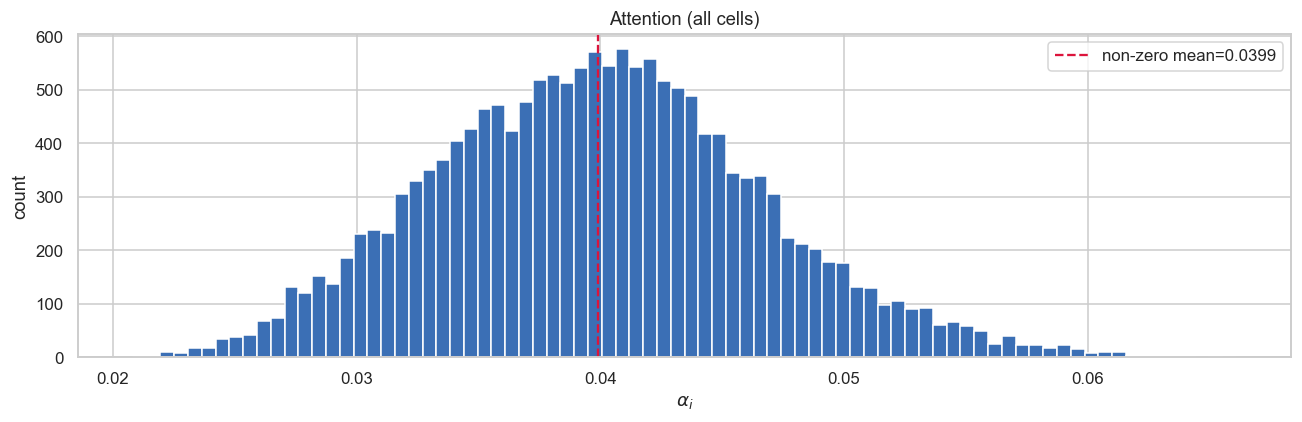

In [7]:
fig, ax = plt.subplots(1, figsize=(12, 4))
ax.hist(a, bins=80, color="#3b6fb5")
ax.set(title="Attention (all cells)", xlabel=r"$\alpha_i$", ylabel="count")
ax.axvline(a[~zero_mask].mean(), color="crimson", ls="--",
           label=f"non-zero mean={a[~zero_mask].mean():.4f}")
ax.legend()

plt.tight_layout();
plt.show()


**Reading this.** The spike at zero is the ~49 % suppressed population. Among the *attended* cells the distribution is smooth and unimodal, peaking below the uniform expectation (`1/bag_size`). This matches the prior observation that the model spreads attention broadly rather than concentrating on a rare outlier subpopulation — biologically consistent with *replicative* senescence being an aggregate, population-wide morphological drift rather than a few fully-senescent cells.


### 2.1 Is zeroing a bag effect or a cell effect?

Because $\alpha_i$ is a softmax **within a bag**, raw zero-rates can be inflated by bag size. We decompose the zeroing into a per-bag component (how many cells each well suppresses) and ask whether some bags zero *everything* (a degenerate bag) versus zeroing being distributed across all bags.


Per-bag fraction zeroed — distribution:
count    159.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0

Bags that zero 100% of cells: 0
Bags that zero   0% of cells: 159


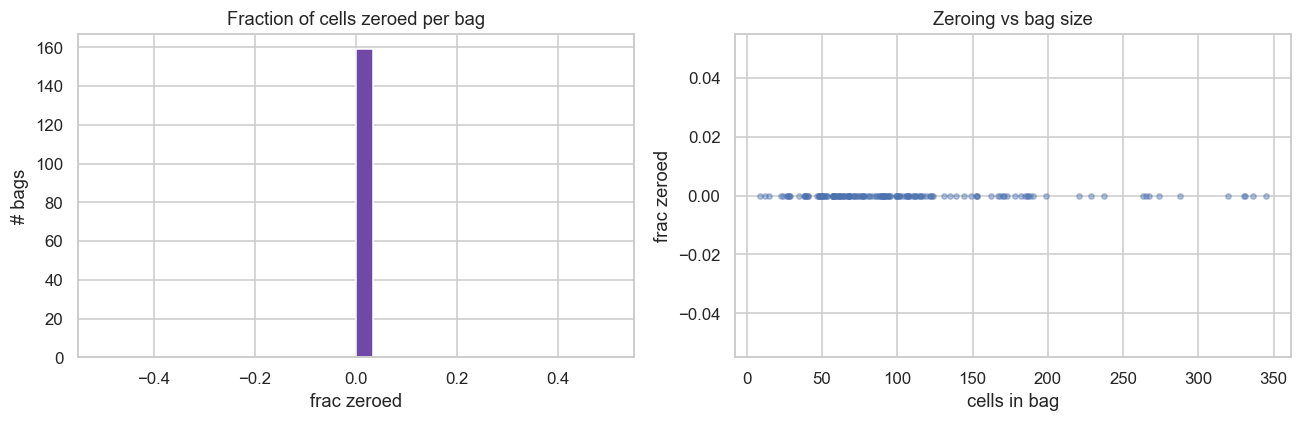

In [8]:
bag = df.groupby("well_name").agg(
    n_cells=("alpha", "size"),
    n_zero=("is_zero", "sum"),
    mean_alpha=("alpha", "mean"),
    passage=("passage", "first"),
    cell_line=("cell_line", "first"),
)
bag["frac_zero"] = bag["n_zero"] / bag["n_cells"]
print("Per-bag fraction zeroed — distribution:")
print(bag["frac_zero"].describe().round(3).to_string())
print(f"\nBags that zero 100% of cells: {(bag.frac_zero==1).sum()}")
print(f"Bags that zero   0% of cells: {(bag.frac_zero==0).sum()}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(bag["frac_zero"], bins=30, color="#7048a8")
ax[0].set(title="Fraction of cells zeroed per bag", xlabel="frac zeroed", ylabel="# bags")
ax[1].scatter(bag["n_cells"], bag["frac_zero"], s=12, alpha=.4)
ax[1].set(title="Zeroing vs bag size", xlabel="cells in bag", ylabel="frac zeroed")
plt.tight_layout(); plt.show()


## 3. What features drive attention?

We correlate each feature with $\alpha_i$. Two correlation views are reported:

- **Global Spearman** across all cells — robust to the heavy zero-inflation and to monotone non-linearity.
- **Within-bag Spearman** — attention is recomputed as a within-well rank, removing bag-level confounds, then correlated. This isolates *what makes a cell win attention against its own bag-mates*, which is the question the model actually answers.

Spearman (rank) correlation is preferred over Pearson because feature scales are wildly heterogeneous (`rawIntDen` ~ 1e8 vs `Solidity` ~ 1) and several features are highly skewed.


In [9]:
feat_cols = man_names + lat_names

# Global Spearman of each feature vs alpha.
glob = pd.Series(
    {f: stats.spearmanr(df[f], df["alpha"]).statistic for f in feat_cols},
    name="spearman_global")

# Within-bag: rank alpha and each feature inside each well, then correlate the ranks.
g = df.groupby("well_name")
alpha_wr = g["alpha"].rank(pct=True)
within = {}
for f in feat_cols:
    fr = g[f].rank(pct=True)
    within[f] = stats.spearmanr(fr, alpha_wr).statistic
within = pd.Series(within, name="spearman_within_bag")

corr = pd.concat([glob, within], axis=1)
corr["feature_type"] = ["manual" if f in man_names else "latent" for f in corr.index]
corr["abs_within"] = corr["spearman_within_bag"].abs()
corr = corr.sort_values("abs_within", ascending=False)
corr.head(20).round(3)


,spearman_global,spearman_within_bag,feature_type,abs_within
mean_3,-0.566,-0.586,manual,0.586
mean_20per_2,-0.553,-0.568,manual,0.568
mean_14,-0.518,-0.531,manual,0.531
var_40per_11,-0.529,-0.529,manual,0.529
var_40per_2,-0.532,-0.525,manual,0.525
ratio4,-0.471,-0.493,manual,0.493
var_20per_5,-0.489,-0.492,manual,0.492
mean_1,-0.445,-0.485,manual,0.485
ratio5,-0.433,-0.467,manual,0.467
ratio6,0.430,0.453,manual,0.453


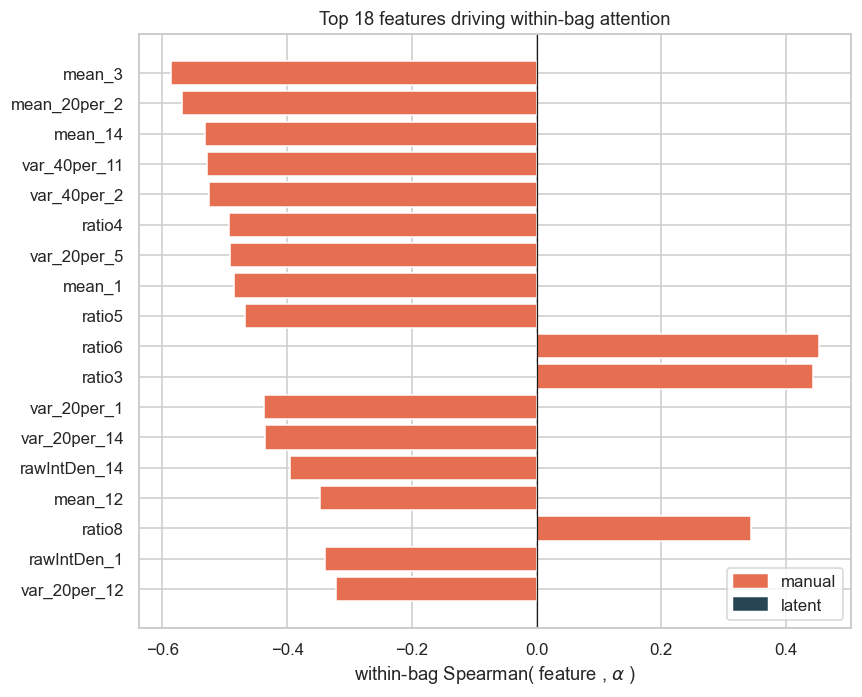

In [10]:
top = corr.head(18).iloc[::-1]
colors = top["feature_type"].map({"manual": "#e76f51", "latent": "#264653"})
plt.figure(figsize=(8, 6.5))
plt.barh(top.index, top["spearman_within_bag"], color=colors)
plt.axvline(0, color="k", lw=.8)
plt.xlabel(r"within-bag Spearman( feature , $\alpha$ )")
plt.title("Top 18 features driving within-bag attention")
from matplotlib.patches import Patch
plt.legend(handles=[Patch(color="#e76f51", label="manual"),
                    Patch(color="#264653", label="latent")], loc="lower right")
plt.tight_layout(); plt.show()


**Interpretation guidance.** Positive within-bag correlation → cells with higher values of that feature *win* attention relative to their well-mates. Negative → such cells are suppressed. Columns are positional (`mcol_NN` / `lcol_NN`); once you map them via `COL_NAME_MAP`, compare the manual drivers against the biological readings established earlier in the project (inter-channel intensity ratios and raw integrated densities as senescence intensity markers; `Area`/`Perimeter`/`Solidity` as enlargement/flattening morphology). Latent dimensions appearing high here flag VAE axes worth decoding via latent traversal.


### 3.1 What distinguishes zeroed-out cells? (group comparison + effect size)

In [11]:
# Compare zeroed vs attended cells per feature: standardised mean difference (Cohen's d)
# computed on robustly-scaled features (median / IQR) so heavy-tailed features behave.
def robust_z(x):
    med = x.median(); iqr = x.quantile(.75) - x.quantile(.25)
    return (x - med) / (iqr if iqr else 1.0)

rz = df[feat_cols].apply(robust_z)
z0 = rz[df["is_zero"].values]
z1 = rz[df["is_attended"].values]

def cohens_d(a, b):
    na, nb = len(a), len(b)
    sp = np.sqrt(((na-1)*a.var() + (nb-1)*b.var()) / (na+nb-2))
    return (a.mean() - b.mean()) / sp if sp else 0.0

eff = pd.Series({f: cohens_d(z1[f], z0[f]) for f in feat_cols}, name="d_attended_minus_zero")
eff = eff.to_frame()
eff["feature_type"] = ["manual" if f in man_names else "latent" for f in eff.index]
eff["abs_d"] = eff["d_attended_minus_zero"].abs()
eff = eff.sort_values("abs_d", ascending=False)
print("Positive d  -> feature is HIGHER in attended cells")
print("Negative d  -> feature is HIGHER in zeroed cells\n")
eff.head(18).round(3)


Positive d  -> feature is HIGHER in attended cells
Negative d  -> feature is HIGHER in zeroed cells



,d_attended_minus_zero,feature_type,abs_d
Area,NaN,manual,NaN
mean_1,NaN,manual,NaN
skew_1,NaN,manual,NaN
rawIntDen_1,NaN,manual,NaN
var_20per_1,NaN,manual,NaN
kurt_40per_1,NaN,manual,NaN
skew_2,NaN,manual,NaN
mean_20per_2,NaN,manual,NaN
var_40per_2,NaN,manual,NaN
kurt_40per_2,NaN,manual,NaN


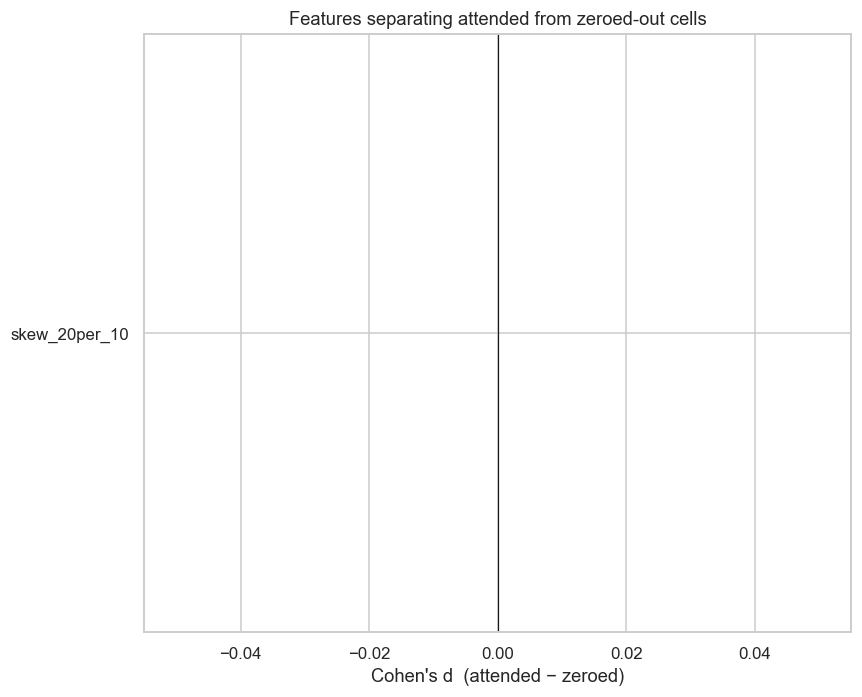

In [12]:
te = eff.head(18).iloc[::-1]
colors = te["feature_type"].map({"manual": "#e76f51", "latent": "#264653"})
plt.figure(figsize=(8, 6.5))
plt.barh(te.index, te["d_attended_minus_zero"], color=colors)
plt.axvline(0, color="k", lw=.8)
plt.xlabel("Cohen's d  (attended − zeroed)")
plt.title("Features separating attended from zeroed-out cells")
plt.tight_layout(); plt.show()


### 3.2 Can we predict whether a cell is zeroed from its features?

A logistic-regression probe quantifies *how predictable* zeroing is from the input features, and its coefficients give a multivariate (de-confounded) view of the drivers. We standardise features, use balanced class weights, and report cross-validated ROC-AUC. High AUC → zeroing is a deterministic function of the inputs; near-0.5 → zeroing is essentially bag-contextual / not explainable by single-cell features alone.


In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, StratifiedGroupKFold
from sklearn.metrics import roc_auc_score

X = df[feat_cols].replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())
y = df["is_zero"].astype(int).values
groups = df["well_name"].values   # keep bags intact across folds

clf = make_pipeline(StandardScaler(),
                    LogisticRegression(max_iter=2000, class_weight="balanced", C=1.0))
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
auc = cross_val_score(clf, X, y, groups=groups, cv=cv, scoring="roc_auc")
print(f"Grouped 5-fold ROC-AUC for predicting 'is_zeroed': "
      f"{auc.mean():.3f} +/- {auc.std():.3f}")

clf.fit(X, y)
coef = pd.Series(clf.named_steps["logisticregression"].coef_[0], index=feat_cols)
coef = coef.reindex(coef.abs().sort_values(ascending=False).index)
print("\nTop coefficients (+ => pushes cell toward being ZEROED):")
print(coef.head(12).round(3).to_string())


ValueError: 
All the 5 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
5 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\goofy\anaconda3\envs\MILAgeScore\Lib\site-packages\sklearn\model_selection\_validation.py", line 833, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\goofy\anaconda3\envs\MILAgeScore\Lib\site-packages\sklearn\base.py", line 1336, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\goofy\anaconda3\envs\MILAgeScore\Lib\site-packages\sklearn\pipeline.py", line 621, in fit
    self._final_estimator.fit(Xt, y, **last_step_params["fit"])
  File "C:\Users\goofy\anaconda3\envs\MILAgeScore\Lib\site-packages\sklearn\base.py

## 4. Feature importance (integrated gradients) and its relation to attention

The importance file holds **global mean |IG|** per feature. A crucial caveat carried over from the project notes:

> **Block-weighting artefact.** IG attributions are computed on the *weighted* input — `features_manual × 4.4376` concatenated with `features_latent × 1.0`. Because IG scales with input magnitude, manual features carry a structural ≈ 4.44× advantage in raw |IG| units. **Do not compare raw manual vs latent |IG| directly.** We therefore also report a within-block normalisation and a magnitude-corrected comparison.


In [ ]:
BLOCK_WEIGHT = 4.4376   # manual-block scaling used at IG time

imp2 = imp.copy()
# Magnitude-corrected IG: undo the manual block's 4.44x advantage.
imp2["ig_corrected"] = np.where(imp2.feature_type == "manual",
                                imp2.global_mean_abs_ig / BLOCK_WEIGHT,
                                imp2.global_mean_abs_ig)
# Within-block rank-normalised IG (0..1 inside each block) for fair cross-block ranking.
imp2["ig_block_norm"] = imp2.groupby("feature_type")["global_mean_abs_ig"]\
                            .transform(lambda s: s / s.max())

print("Total raw |IG| by block (uncorrected):")
print(imp.groupby("feature_type").global_mean_abs_ig.sum().round(3).to_string())
print("\nTotal |IG| by block AFTER magnitude correction:")
print(imp2.groupby("feature_type").ig_corrected.sum().round(3).to_string())
print("\nMean |IG| per feature by block (corrected):")
print(imp2.groupby("feature_type").ig_corrected.mean().round(4).to_string())


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 6))
# Raw top-15
t1 = imp.sort_values("global_mean_abs_ig", ascending=False).head(15).iloc[::-1]
c1 = t1.feature_type.map({"manual":"#e76f51","latent":"#264653"})
ax[0].barh(t1.feature, t1.global_mean_abs_ig, color=c1)
ax[0].set_title("Top 15 by RAW mean |IG|\n(manual block inflated ~4.44x)")
ax[0].set_xlabel("mean |IG|")
# Corrected top-15
t2 = imp2.sort_values("ig_corrected", ascending=False).head(15).iloc[::-1]
c2 = t2.feature_type.map({"manual":"#e76f51","latent":"#264653"})
ax[1].barh(t2.feature, t2.ig_corrected, color=c2)
ax[1].set_title("Top 15 by MAGNITUDE-CORRECTED |IG|")
ax[1].set_xlabel("corrected mean |IG|")
from matplotlib.patches import Patch
ax[1].legend(handles=[Patch(color="#e76f51",label="manual"),
                      Patch(color="#264653",label="latent")], loc="lower right")
plt.tight_layout(); plt.show()


**Reading the correction.** Compare the two panels. Features that stay near the top after correction are robustly important; manual features that *drop* were riding the block-weight advantage. Note that IG importance is a **model-global** statement (how much a feature moves the *passage prediction*), whereas attention is a **per-cell bag-relative** statement. They answer different questions — which is exactly why Section 4.1 tests whether they coincide.


### 4.1 Do high-importance features coincide with high attention?

We test this directly: for each feature, is its **IG importance** related to its **attention-driving strength** (the within-bag Spearman from Section 3)? If the same features that move the prediction also win attention, the two correlate positively across features.

> **Requires `COL_NAME_MAP`.** This test joins the named IG table to the per-column attention correlations, so it needs the positional columns mapped to importance-file names. With positional labels it cannot run on the **manual** block (names don't match). The **latent** block *can* be tested if you map `latent_NN` positional columns to the `latent_K` names from the importance file. The cell below runs the test for whatever subset of columns you have mapped to importance names, and reports `n` so you know the coverage.


In [ ]:
# Join on whatever column labels currently coincide with importance-file feature names.
imp_named = imp.set_index("feature")
ig_lookup  = imp_named["global_mean_abs_ig"]
igc_lookup = imp2.set_index("feature")["ig_corrected"]

link = corr.copy()
link["global_mean_abs_ig"] = link.index.map(ig_lookup)
link["ig_corrected"]       = link.index.map(igc_lookup)
link = link.dropna(subset=["global_mean_abs_ig"])

if len(link) < 3:
    print("Cannot run IG-vs-attention correlation: only", len(link),
          "feature columns are mapped to importance-file names.")
    print("Populate COL_NAME_MAP in section 1.1 with your true export order, then re-run.")
else:
    for blk in ["manual", "latent"]:
        sub = link[link.feature_type == blk]
        if len(sub) >= 3:
            r = stats.spearmanr(sub["ig_corrected"], sub["abs_within"])
            print(f"{blk:6s}: Spearman( corrected |IG| , |attn-corr| ) = "
                  f"{r.statistic:+.3f}  (p={r.pvalue:.3g}, n={len(sub)})")
    r_all = stats.spearmanr(link["ig_corrected"], link["abs_within"])
    print(f"all   : Spearman = {r_all.statistic:+.3f} (p={r_all.pvalue:.3g}, n={len(link)})")


In [ ]:
if len(link) >= 3:
    plt.figure(figsize=(8, 6))
    for blk, col in [("manual","#e76f51"), ("latent","#264653")]:
        sub = link[link.feature_type == blk]
        if len(sub):
            plt.scatter(sub["ig_corrected"], sub["abs_within"], c=col, label=blk, alpha=.8, s=45)
    ann = link.sort_values("ig_corrected", ascending=False).head(6)
    for f, row in ann.iterrows():
        plt.annotate(f, (row["ig_corrected"], row["abs_within"]),
                     fontsize=8, xytext=(4,3), textcoords="offset points")
    plt.xlabel("magnitude-corrected mean |IG|  (global importance)")
    plt.ylabel(r"|within-bag Spearman with $\alpha$|  (attention-driving)")
    plt.title("Global importance vs attention-driving strength, per feature")
    plt.legend(); plt.tight_layout(); plt.show()
else:
    print("Plot skipped — map COL_NAME_MAP first (see message above).")


**How to interpret.** A *positive* cross-feature correlation supports the hypothesis that the model attends to cells expressing the features it deems globally important for the passage prediction — i.e. attention and importance are aligned. A *weak / null* correlation indicates a division of labour: importance reflects *what the embedding encodes about age*, attention reflects *which cells the pooling step trusts*, and these need not be the same features. Report whichever the data show; do not assume alignment. **Note:** this test runs only over feature columns you have mapped to importance-file names via `COL_NAME_MAP`.


### 4.2 Sanity check — attention vs biological age (passage)

In [ ]:
byp = df.groupby("passage").agg(
    mean_alpha=("alpha","mean"),
    frac_zero=("is_zero","mean"),
    n=("alpha","size"))
fig, ax = plt.subplots(1, 2, figsize=(12,4))
ax[0].plot(byp.index, byp["mean_alpha"], "o-", color="#2a9d8f")
ax[0].set(title="Mean attention vs passage", xlabel="passage", ylabel=r"mean $\alpha$")
ax[1].plot(byp.index, byp["frac_zero"], "o-", color="#7048a8")
ax[1].set(title="Fraction zeroed vs passage", xlabel="passage", ylabel="frac zeroed")
plt.tight_layout(); plt.show()
byp.round(4)


In [ ]:
import lightgbm as lgb
import shap
from sklearn.model_selection import train_test_split

# ── Prepare data ──────────────────────────────────────────────────────────
X = df_full[all_feat_cols].copy()
y = df_full['mean_attention'].copy()

# Drop rows with any NaNs across features/target (SHAP/LightGBM need clean input)
valid_mask = X.notna().all(axis=1) & y.notna()
X, y = X[valid_mask], y[valid_mask]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ── Fit surrogate model ──────────────────────────────────────────────────
model = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
)

model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    eval_metric='rmse',
    callbacks=[lgb.early_stopping(stopping_rounds=30, verbose=False)],
)

train_r2 = model.score(X_train, y_train)
test_r2 = model.score(X_test, y_test)
print(f"Surrogate fit quality — train R²: {train_r2:.4f} | test R²: {test_r2:.4f}")

# ── SHAP values ───────────────────────────────────────────────────────────
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

# ── Global ranked feature importance (mean |SHAP|) ──────────────────────
shap_importance = pd.DataFrame({
    'feature': X_test.columns,
    'feature_type': ['manual' if c in manual_cols else 'latent' for c in X_test.columns],
    'mean_abs_shap': np.abs(shap_values).mean(axis=0),
}).sort_values('mean_abs_shap', ascending=False).reset_index(drop=True)

print("\nTop 15 features driving attention (mean |SHAP|):")
print(shap_importance.head(15).to_string(index=False))

# ── Plots ─────────────────────────────────────────────────────────────────
shap.summary_plot(shap_values, X_test, max_display=20, show=True)

# Dependence plots for top 4 features — reveals monotonic / threshold / U-shape behaviour
top_feats = shap_importance['feature'].head(4).tolist()
for feat in top_feats:
    shap.dependence_plot(feat, shap_values, X_test, show=True)